# A Finite Calculation from Supplied Priors

This native Julia companion preserves the original equations, supplied probability laws, approved NASDAQ observations, calendar grouping, population moments, bins, weights, comparisons and assertions. Both tails remain explicit. Native figures use the requested dark theme; Julia tables and figures are saved under `outputs/julia`.

## Discretizing monthly return laws

For month \(j\), let the supplied normal return law have mean \(\mu_j\) and standard deviation \(\sigma_j>0\). If the interior bin has lower edge \(a_k\) and upper edge \(b_k\), its probability is

$$
p_{j,k}=\Phi\left(\frac{b_k-\mu_j}{\sigma_j}\right)-\Phi\left(\frac{a_k-\mu_j}{\sigma_j}\right).
$$

Here, \(p_{j,k}\) is the probability assigned by monthly law \(j\) to bin \(k\); \(\Phi\) is the standard normal cumulative distribution function; \(a_k\) and \(b_k\) are bin edges; \(\mu_j\) is the monthly mean daily return; and \(\sigma_j\) is the monthly population standard deviation. The lower and upper tail probabilities are included as separate bins, so every row sums to one.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("04_probability_ambiguity");
using CSV, Printf
using RiskLabAI.Features: probability_ambiguity, normal_prior_bin_probabilities

function load_public_data()
    data_path = dataset_path("fred_nasdaq")
    @assert isfile(data_path)
    raw = CSV.read(data_path,DataFrame;missingstring=["", "."])
    data = dropmissing(raw,:NASDAQCOM)
    sort!(data,:observation_date)
    rename!(data,:observation_date=>"Date",:NASDAQCOM=>"NASDAQ Composite")
    data.Date = Date.(data.Date)
    prices = data[!,"NASDAQ Composite"]
    data[!,"Daily log return"] = vcat(NaN,log.(prices[2:end]./prices[1:end-1]))
    data.Year = year.(data.Date)
    data.Month = month.(data.Date)
    return data
end

function monthly_moments(data)
    returns = data[isfinite.(data[!,"Daily log return"]),:]
    return combine(groupby(returns,[:Year,:Month];sort=true),"Daily log return"=>mean=>:Mean,"Daily log return"=>(values->std(values;corrected=false))=>:Standard_deviation,"Daily log return"=>length=>:Observations)
end

normal_edges(width) = collect(range(-.06,.06;length=round(Int,.12/width)+1))
percent_label(value) = @sprintf("%g%%",100value)
bin_labels(edges) = vcat("Below "*percent_label(first(edges)),[percent_label(left)*" to "*percent_label(right) for (left,right) in zip(edges[1:end-1],edges[2:end])],"Above "*percent_label(last(edges)))


bin_labels (generic function with 1 method)

In [2]:
data = load_public_data()
moments = monthly_moments(data)
worked = moments[moments.Year.==1994,:]
@assert nrow(worked) == 12
worked[!,"Month name"] = monthabbr.(Date.(1994,worked.Month,1))
monthly_table = select(worked,"Month name",:Observations)
monthly_table[!,"Mean daily return (%)"] = 100 .* worked.Mean
monthly_table[!,"Daily standard deviation (%)"] = 100 .* worked.Standard_deviation
save_table(monthly_table,paths,"monthly_priors_1994";caption="Monthly normal laws estimated from public daily returns in 1994.",label="tab:chapter5-monthly-priors-1994")
selection = DataFrame("Selection rule"=>["First complete calendar year by date"],"Year"=>[1994],"Monthly laws"=>[nrow(worked)],"Daily returns"=>[sum(worked.Observations)],"Minimum returns in a month"=>[minimum(worked.Observations)],"Maximum returns in a month"=>[maximum(worked.Observations)])
save_table(selection,paths,"worked_year_selection";caption="Date based selection of the worked decomposition year.",label="tab:chapter5-worked-year-selection")
edges = normal_edges(.002)
labels = bin_labels(edges)
probabilities = normal_prior_bin_probabilities(worked.Mean,worked.Standard_deviation;edges)
prior_weights = fill(1/nrow(worked),nrow(worked))
result = probability_ambiguity(probabilities;prior_weights,bin_width=.002)
@assert size(probabilities) == (12,62)
@assert all(probabilities.>=0)
@assert vec(sum(probabilities;dims=2)) ≈ ones(12)
x_grid = collect(range(-.06,.06;length=601))
density_rows = NamedTuple[]
for row in eachrow(worked), value in x_grid
    density = exp(-.5*((value-row.Mean)/row.Standard_deviation)^2)/(sqrt(2pi)*row.Standard_deviation)
    push!(density_rows,(;month=row["Month name"],daily_return=100value,density=density/100))
end
density_frame = DataFrame(density_rows)
rename!(density_frame,["Month","Daily return (%)","Density"])
save_data(density_frame,paths,"monthly_normal_densities_1994")
matrix_rows = [(;month=worked[j,"Month name"],bin=k,label=labels[k],probability=probabilities[j,k]) for j in 1:12 for k in eachindex(labels)]
matrix_frame = DataFrame(matrix_rows)
rename!(matrix_frame,["Month","Bin number","Bin","Probability"])
save_data(matrix_frame,paths,"bin_probability_matrix_1994");


Row,Month name,Observations,Mean daily return (%),Daily standard deviation (%)
,String,Int64,Float64,Float64
1,Jan,20,0.18911,0.342269
2,Feb,19,-0.052666,0.788022
3,Mar,23,-0.277728,0.752982
4,Apr,19,-0.0685471,1.22822
5,May,21,0.00875213,0.675294
6,Jun,22,-0.184411,0.779227
7,Jul,20,0.113441,0.557226
8,Aug,23,0.254084,0.382399
9,Sep,21,-0.00827936,0.621371


Row,Selection rule,Year,Monthly laws,Daily returns,Minimum returns in a month,Maximum returns in a month
,String,Int64,Int64,Int64,Int64,Int64
1,First complete calendar year by date,1994,12,251,19,23


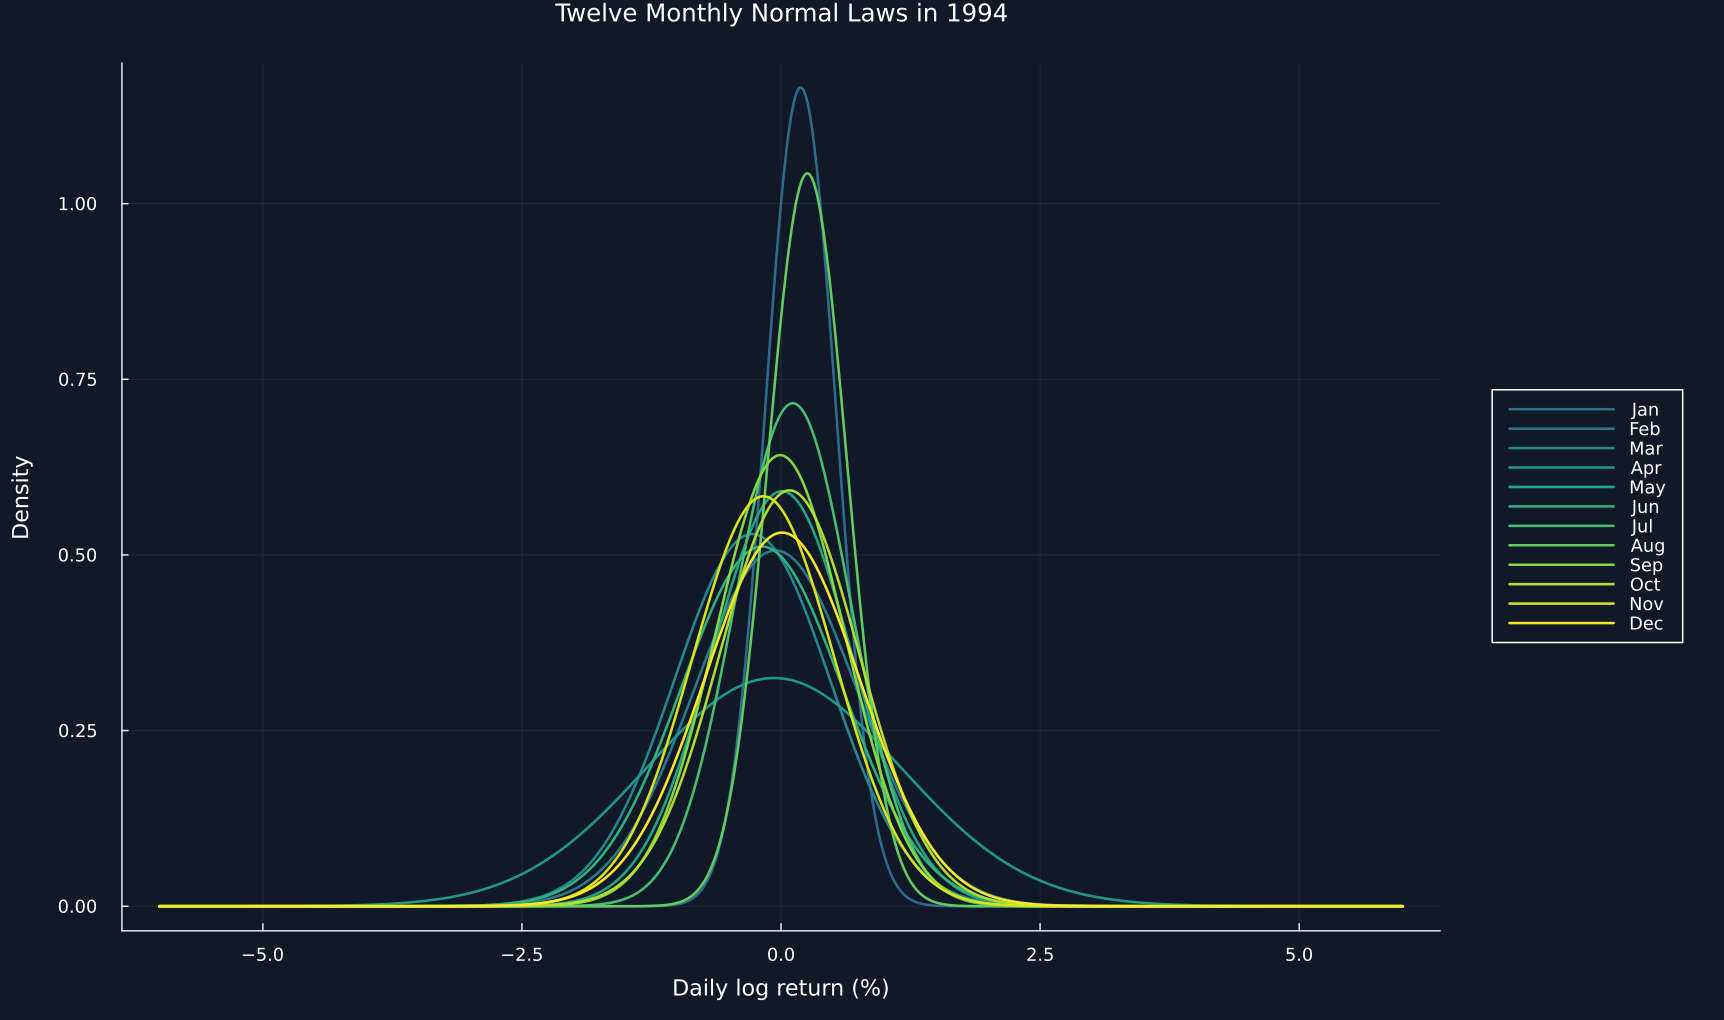

In [3]:
figure = plot(;xlabel="Daily log return (%)",ylabel="Density",title="Twelve Monthly Normal Laws in 1994",legend=:outerright,size=(1150,680))
colors = [Plots.cgrad(:viridis)[value] for value in range(.35,1.;length=12)]
for (name,color) in zip(worked[!,"Month name"],colors)
    part = density_frame[density_frame.Month.==name,:]
    plot!(figure,part[!,"Daily return (%)"],part.Density;color,linewidth=1.7,label=name)
end
save_figure(figure,paths,"monthly_normal_laws_1994")


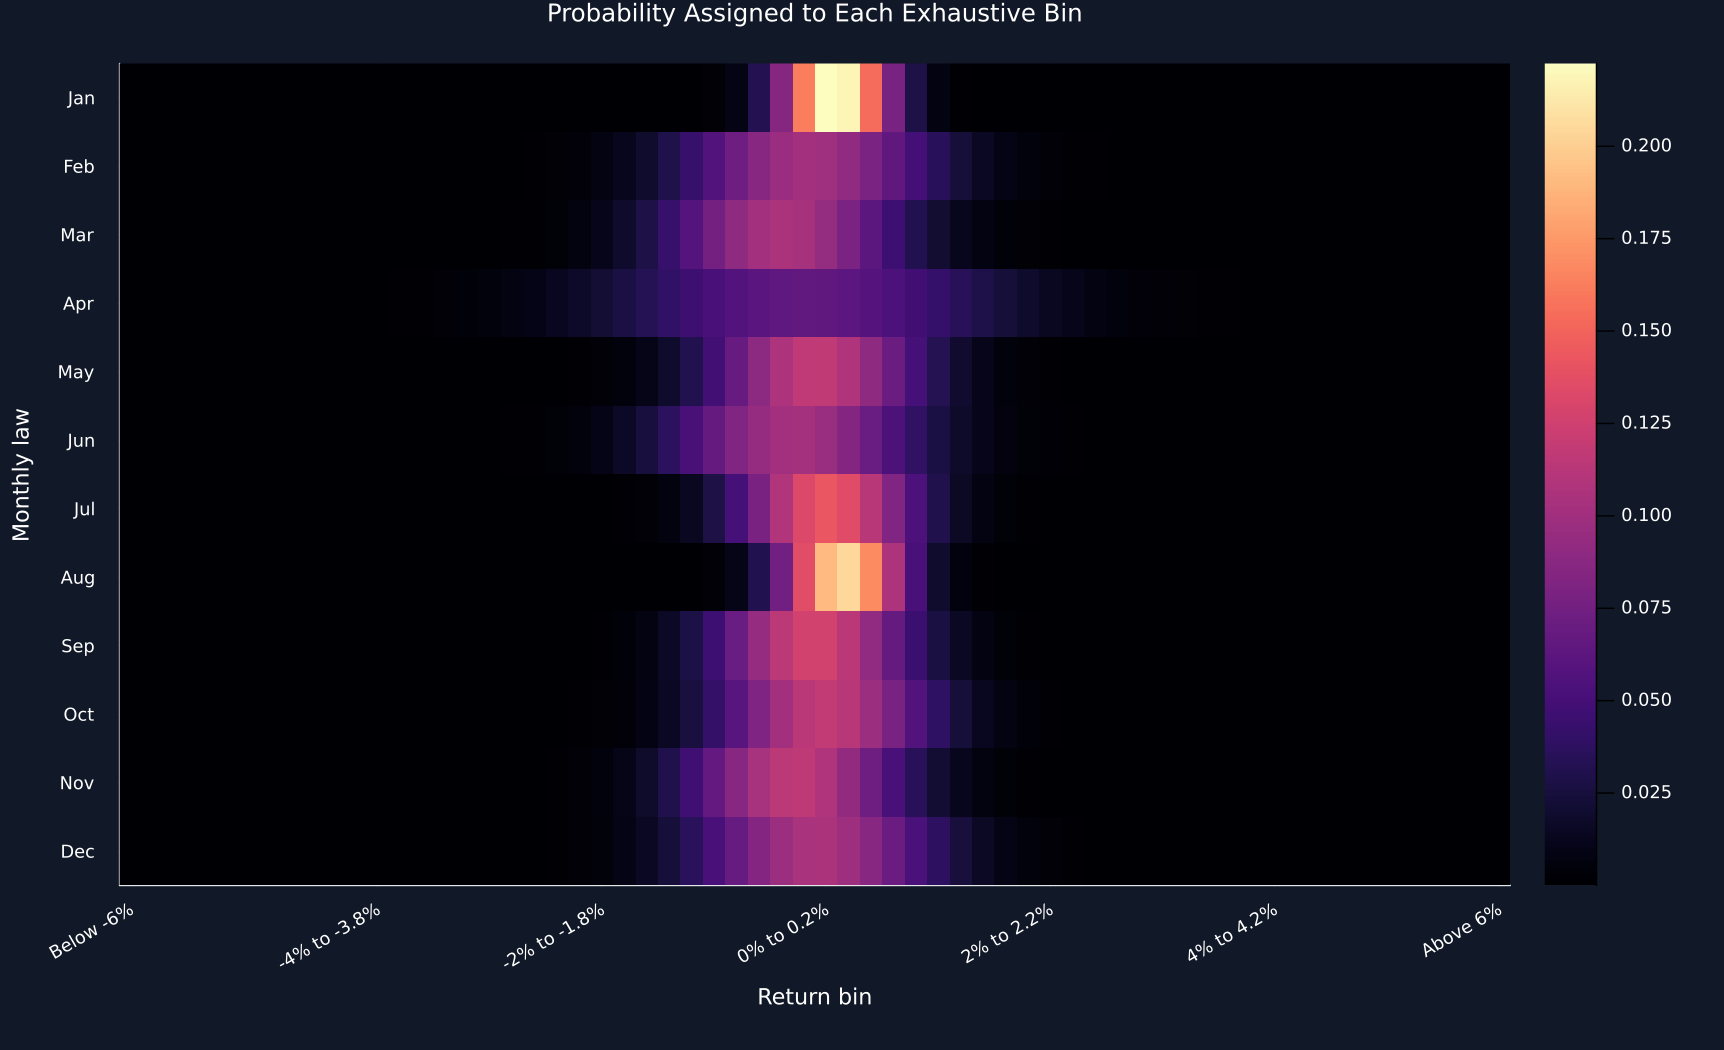

In [4]:
tick_positions = [1,12,22,32,42,52,62]
figure = heatmap(1:62,1:12,probabilities;c=:magma,yflip=true,yticks=(1:12,worked[!,"Month name"]),xticks=(tick_positions,labels[tick_positions]),xrotation=30,xlabel="Return bin",ylabel="Monthly law",title="Probability Assigned to Each Exhaustive Bin",size=(1150,700),bottom_margin=12Plots.mm)
save_figure(figure,paths,"bin_probability_matrix_1994")


## Decomposing ambiguity across states

With equal weights \(q_j=1/12\), the finite measure is built in three steps:

$$
\bar p_k=\sum_{j=1}^{12}q_jp_{j,k},
\qquad
v_k=\sum_{j=1}^{12}q_j(p_{j,k}-\bar p_k)^2,
\qquad
c_k=\bar p_kv_k.
$$

Here, \(\bar p_k\) is the average probability of bin \(k\); \(v_k\) is the population variance of that probability across the twelve laws; and \(c_k\) is the contribution of the bin. The unscaled ambiguity measure is the sum \(A=\sum_kc_k\). A bin contributes only when it has both positive average probability and disagreement across laws.

In [5]:
mean_probability,probability_variance = result.mean_probabilities,result.probability_variances
contribution = mean_probability.*probability_variance
contribution_frame = DataFrame("Bin number"=>collect(eachindex(labels)),"Bin"=>labels,"Mean probability"=>mean_probability,"Probability variance"=>probability_variance,"Contribution"=>contribution)
save_data(contribution_frame,paths,"bin_contributions_1994")
top_contributions = first(sort(contribution_frame,"Contribution";rev=true),10)[:,["Bin","Mean probability","Probability variance","Contribution"]]
save_table(top_contributions,paths,"largest_bin_contributions_1994";caption="Ten largest bin contributions to the 1994 ambiguity measure.",label="tab:chapter5-largest-bin-contributions-1994")
selected_indices = [1,22,27,31,32,36,41,62]
excerpt = DataFrame("Bin"=>labels[selected_indices])
for month_index in [1,4,8,12]
    excerpt[!,worked[month_index,"Month name"]] = probabilities[month_index,selected_indices]
end
save_table(excerpt,paths,"bin_probability_excerpt_1994";caption="Selected bin probabilities for four monthly laws.",label="tab:chapter5-bin-probability-excerpt-1994")
summary = DataFrame("Quantity"=>["Monthly laws","Interior bins","Tail bins","Unscaled ambiguity","Scaled ambiguity","Interior bin width"],"Value"=>[12,60,2,result.unscaled,result.scaled,.002])
save_table(summary,paths,"ambiguity_summary_1994";caption="Summary of the 1994 finite ambiguity calculation.",label="tab:chapter5-ambiguity-summary-1994")


Row,Bin,Mean probability,Probability variance,Contribution
,String,Float64,Float64,Float64
1,0.2% to 0.4%,0.116462,0.00213468,0.000248609
2,0% to 0.2%,0.123419,0.00175812,0.000216984
3,0.4% to 0.6%,0.0951353,0.00109502,0.000104175
4,-0.2% to 0%,0.114807,0.000522573,5.99951e-5
5,-0.6% to -0.4%,0.0779395,0.000546314,4.25794e-5
6,-0.8% to -0.6%,0.060137,0.000644421,3.87535e-5
7,-1% to -0.8%,0.0445613,0.00050634,2.25631e-5
8,-0.4% to -0.2%,0.0972557,0.000225139,2.1896e-5
9,0.6% to 0.8%,0.068325,0.000252984,1.72851e-5


Row,Bin,Jan,Apr,Aug,Dec
,String,Float64,Float64,Float64,Float64
1,Below -6%,2.18583e-73,6.85067e-7,2.00745e-60,5.63762e-16
2,-2% to -1.8%,3.01529e-9,0.0214004,3.71474e-8,0.0042219
3,-1% to -0.8%,0.00167088,0.0516287,0.00240122,0.0509999
4,-0.2% to 0%,0.162497,0.0648696,0.135679,0.104912
5,0% to 0.2%,0.222394,0.0642841,0.190562,0.105298
6,0.8% to 1%,0.0282307,0.0475826,0.0511511,0.0527141
7,1.8% to 2%,1.19916e-6,0.0180134,2.39323e-5,0.00452709
8,Above 6%,6.02144e-65,3.88773e-7,2.48084e-51,7.06061e-16


Row,Quantity,Value
,String,Float64
1,Monthly laws,12.0
2,Interior bins,60.0
3,Tail bins,2.0
4,Unscaled ambiguity,0.000797964
5,Scaled ambiguity,0.399782
6,Interior bin width,0.002


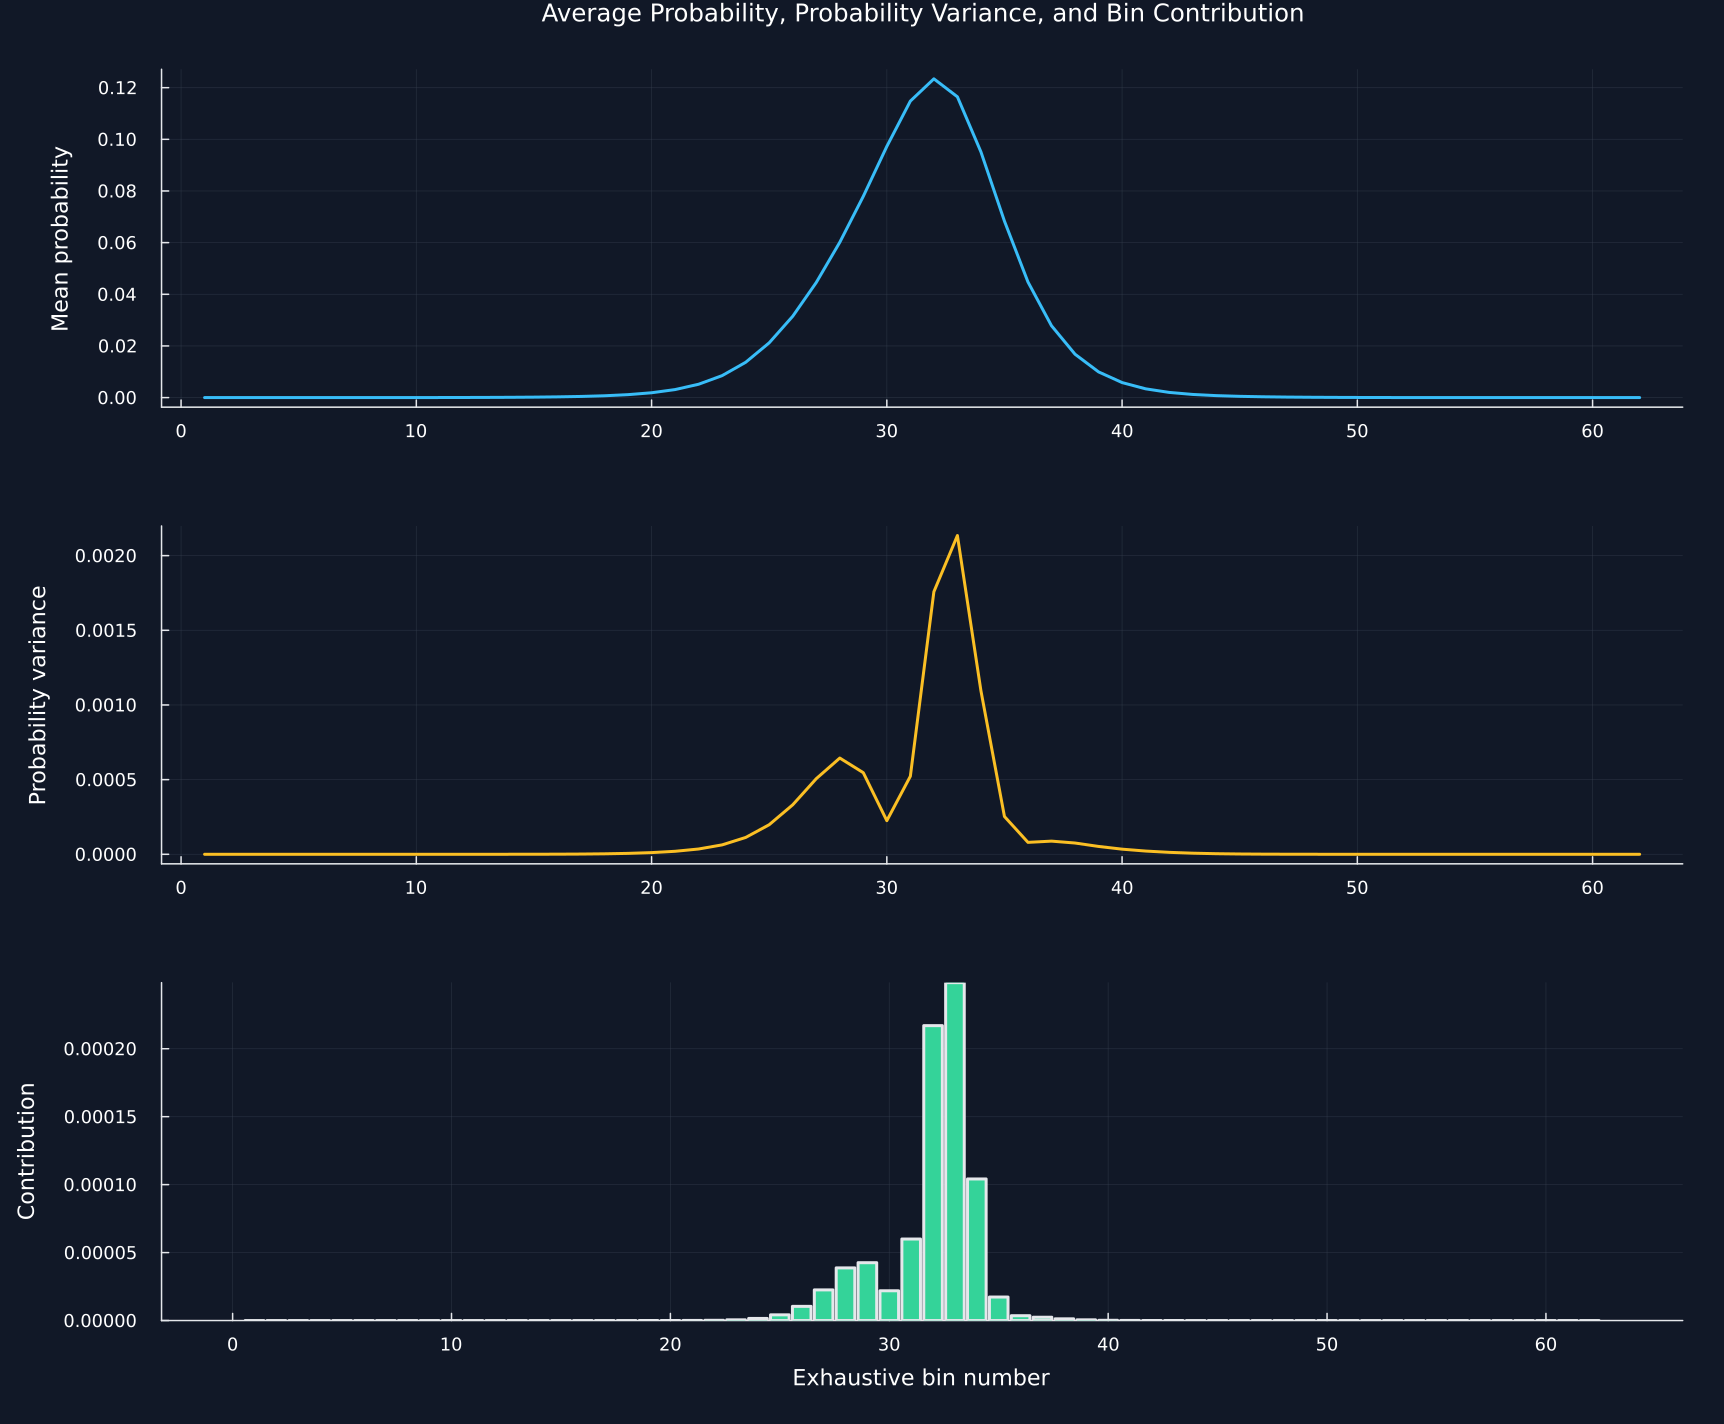

In [6]:
positions = contribution_frame[!,"Bin number"]
top = plot(positions,mean_probability;color=palette.cyan,ylabel="Mean probability",title="Average Probability, Probability Variance, and Bin Contribution",label=false)
middle = plot(positions,probability_variance;color=palette.amber,ylabel="Probability variance",label=false)
bottom = bar(positions,contribution;color=palette.green,bar_width=.85,ylabel="Contribution",xlabel="Exhaustive bin number",label=false)
save_figure(plot(top,middle,bottom;layout=(3,1),size=(1150,950)),paths,"bin_contributions_1994")


## Validating the ambiguity calculation

The contribution of disagreement between laws \(i\) and \(j\) can be written as

$$
C_{ij}=\frac{q_iq_j}{2}\sum_{k=1}^{K}\bar p_k(p_{i,k}-p_{j,k})^2.
$$

Here, \(C_{ij}\) is the ordered pair contribution; \(q_i\) and \(q_j\) are the two prior weights; and the remaining symbols retain their earlier meanings. Summing \(C_{ij}\) over every ordered pair gives \(A\). The diagonal is zero because a law cannot disagree with itself.

For interior bin width \(h\), the reported scaled measure is

$$
A^{\mathrm{scaled}}=\frac{A}{h(1-h)}.
$$

Here, \(A^{\mathrm{scaled}}\) is the scaled value and \(0<h<1\) is the interior bin width expressed in return units. Scaling reduces the mechanical size effect of the grid, but it does not make the value independent of the grid.

In [7]:
pair_matrix = [.5*prior_weights[i]*prior_weights[j]*sum(mean_probability.*(probabilities[i,:].-probabilities[j,:]).^2) for i in 1:12,j in 1:12]
@assert sum(pair_matrix) ≈ result.unscaled
pair_rows = [(;first=worked[i,"Month name"],second=worked[j,"Month name"],contribution=2pair_matrix[i,j]) for i in 1:12 for j in i+1:12]
pair_frame = DataFrame(pair_rows)
rename!(pair_frame,["First month","Second month","Combined pair contribution"])
save_table(first(sort(pair_frame,"Combined pair contribution";rev=true),10),paths,"largest_month_pairs_1994";caption="Ten monthly pairs with the largest combined contribution.",label="tab:chapter5-largest-month-pairs-1994")
pair_data = DataFrame(pair_matrix,worked[!,"Month name"])
insertcols!(pair_data,1,"First month"=>worked[!,"Month name"])
save_data(pair_data,paths,"pairwise_dispersion_1994")
scaled_probabilities = normal_prior_bin_probabilities(100 .* worked.Mean,100 .* worked.Standard_deviation;edges=100 .* edges)
unit_difference = maximum(abs.(probabilities.-scaled_probabilities))
permutation = [12,1,8,4,10,3,7,2,11,6,9,5]
permuted = probability_ambiguity(probabilities[permutation,:];prior_weights=prior_weights[permutation],bin_width=.002)
direct_value = dot(mean_probability,probability_variance)
checks = DataFrame("Check"=>["Every monthly probability row sums to one","All bin probabilities are nonnegative","Direct sum agrees with the library value","Pairwise identity agrees with the library value","Permutation leaves the value unchanged","Percent and decimal units give the same probabilities","Scaled value follows the stated relation"],"Maximum difference"=>[maximum(abs.(sum(probabilities;dims=2).-1)),max(0.,-minimum(probabilities)),abs(direct_value-result.unscaled),abs(sum(pair_matrix)-result.unscaled),abs(permuted.unscaled-result.unscaled),unit_difference,abs(result.scaled-result.unscaled/(.002*.998))],"Result"=>fill("Pass",7))
@assert all(checks[!,"Maximum difference"].<1e-12)
save_table(checks,paths,"finite_identity_checks_1994";caption="Checks of the 1994 finite calculation.",label="tab:chapter5-finite-identity-checks-1994")
grid = DataFrame("Item"=>["Lower finite edge","Upper finite edge","Interior bin width","Interior bins","Tail bins","Total bins"],"Value"=>[-.06,.06,.002,60,2,62])
save_table(grid,paths,"default_grid_definition";caption="Default exhaustive grid for the finite calculation.",label="tab:chapter5-default-grid-definition")
units = DataFrame("Input representation"=>["Decimal returns","Percentage point returns"],"Mean multiplier"=>[1,100],"Standard deviation multiplier"=>[1,100],"Edge multiplier"=>[1,100],"Maximum probability difference"=>[0.,unit_difference])
save_table(units,paths,"return_unit_consistency";caption="Equivalent normal-bin probabilities under consistent return units.",label="tab:chapter5-return-unit-consistency")


Row,First month,Second month,Combined pair contribution
,String,String,Float64
1,Jan,Apr,5.90421e-5
2,Jan,Mar,4.74343e-5
3,Apr,Aug,4.68786e-5
4,Jan,Jun,4.31058e-5
5,Mar,Aug,3.99659e-5
6,Jan,Nov,3.84911e-5
7,Jan,Feb,3.8084e-5
8,Jun,Aug,3.52598e-5
9,Jan,Dec,3.37383e-5


Row,Check,Maximum difference,Result
,String,Float64,String
1,Every monthly probability row sums to one,3.33067e-16,Pass
2,All bin probabilities are nonnegative,0.0,Pass
3,Direct sum agrees with the library value,1.0842e-19,Pass
4,Pairwise identity agrees with the library value,1.0842e-19,Pass
5,Permutation leaves the value unchanged,1.0842e-19,Pass
6,Percent and decimal units give the same probabilities,1.11022e-16,Pass
7,Scaled value follows the stated relation,0.0,Pass


Row,Item,Value
,String,Float64
1,Lower finite edge,-0.06
2,Upper finite edge,0.06
3,Interior bin width,0.002
4,Interior bins,60.0
5,Tail bins,2.0
6,Total bins,62.0


Row,Input representation,Mean multiplier,Standard deviation multiplier,Edge multiplier,Maximum probability difference
,String,Int64,Int64,Int64,Float64
1,Decimal returns,1,1,1,0.0
2,Percentage point returns,100,100,100,1.11022e-16


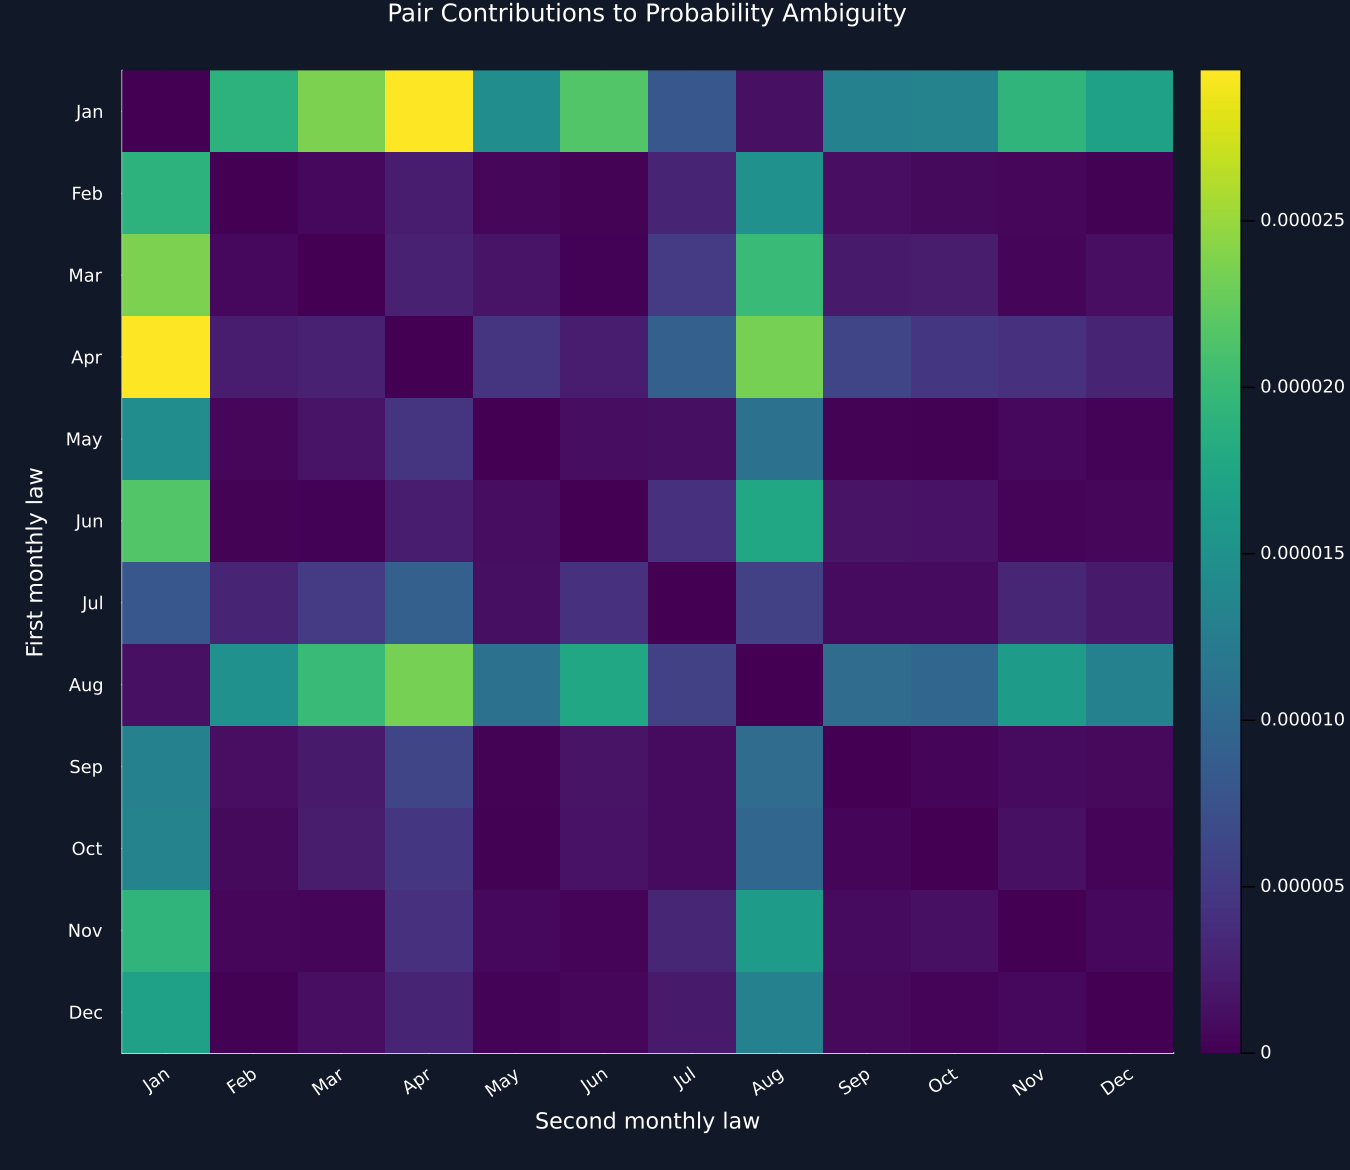

In [8]:
figure = heatmap(1:12,1:12,pair_matrix;c=:viridis,yflip=true,xticks=(1:12,worked[!,"Month name"]),yticks=(1:12,worked[!,"Month name"]),xrotation=35,xlabel="Second monthly law",ylabel="First monthly law",title="Pair Contributions to Probability Ambiguity",size=(900,780))
save_figure(figure,paths,"pairwise_dispersion_1994")
